# MS6 — De l'analyse à la production : clustering routier, capacitaire et robuste
### Volet 3/3 du travail data science — *stratégie de production*

**PFE Master SDIA — Transport scolaire intelligent · Anass Zbir · Pr. Ali Bekri · FS Meknès**

---

Les notebooks 1 (EDA/CRISP-DM) et 2 (benchmark de 11 algorithmes) ont établi deux constats honnêtes :
1. la contrainte de capacité **rigide** (groupes strictement égaux à k minimal) dégrade fortement la
   qualité (Silhouette 0.51 → 0.38) ;
2. l'évaluation à **vol d'oiseau** sous-estime la réalité du ramassage.

Ce notebook construit la **stratégie de production** qui corrige ces deux points :

| Levier | Réponse apportée |
|---|---|
| Distance réelle | **Matrice routière OSRM** (réseau de Meknès) au lieu de l'euclidien |
| Affectation aux bus | **k-médoïdes capacitaire routier** (affectation par *flot à coût minimal*, `taille ≤ capacité`) |
| Élèves dispersés | **détection + traitement séparé** (ramassage individuel) |
| Arbitrage flotte | **courbe de Pareto** qualité/compacité **vs nombre de bus** (décision métier) |

> Reproductible : la matrice OSRM est **mise en cache** (`data/osrm_dist_m.npy`). Si le cache est
> absent, le notebook la reconstruit depuis OSRM (`localhost:5000`) ; si OSRM est indisponible, il
> bascule sur la distance à vol d'oiseau (résultats dégradés, signalés).

## 0. Données, projection et matrice de distances routières

**🔎 Approche.** On charge les élèves, on projette en mètres (pour les baselines euclidiennes) et on fixe la capacité du bus.

In [1]:
import math, json, time, warnings, urllib.request
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colormaps
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110

BUS_CAPACITY = 50
DATA = Path("../data"); FIG = Path("figures"); FIG.mkdir(exist_ok=True)
def savefig(n): plt.tight_layout(); plt.savefig(FIG / n, dpi=130, bbox_inches="tight")

df = pd.read_csv(DATA / "eleves_meknes.csv")
N = len(df)
lat, lon = df["latitude"].values, df["longitude"].values
lat0, lon0 = lat.mean(), lon.mean()
XY = np.column_stack([np.radians(lon-lon0)*6371000*math.cos(math.radians(lat0)),
                      np.radians(lat-lat0)*6371000])           # mètres (euclidien)
ECOLE = (df["ecole_lat"].iloc[0], df["ecole_lng"].iloc[0])
print(f"{N} élèves | capacité bus = {BUS_CAPACITY}")

300 élèves | capacité bus = 50


**🔎 Approche.** On récupère la matrice de distances **routières** (réseau réel via OSRM), en privilégiant le cache pour la reproductibilité, avec repli automatique sur le vol d'oiseau si OSRM est éteint.

In [2]:
# Distance à vol d'oiseau (référence) et matrice ROUTIÈRE OSRM (cache -> live -> repli)
def haversine_matrix(LAT, LON):
    R = 6_371_000.0; la = np.radians(LAT)[:, None]; lo = np.radians(LON)[:, None]
    dla = la - la.T; dlo = lo - lo.T
    a = np.sin(dla/2)**2 + np.cos(la)*np.cos(la.T)*np.sin(dlo/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

HV = haversine_matrix(lat, lon)

def build_osrm(LAT, LON, block=50, url="http://localhost:5000"):
    n = len(LAT); D = np.full((n, n), np.nan)
    blocks = [list(range(i, min(i+block, n))) for i in range(0, n, block)]
    for bi in blocks:
        for bj in blocks:
            idx = bi + bj
            coords = ";".join(f"{LON[k]},{LAT[k]}" for k in idx)
            s = ";".join(str(i) for i in range(len(bi)))
            d = ";".join(str(i) for i in range(len(bi), len(idx)))
            u = f"{url}/table/v1/driving/{coords}?annotations=distance&sources={s}&destinations={d}"
            with urllib.request.urlopen(u, timeout=60) as r:
                dist = np.array(json.load(r)["distances"], float)
            for a, gi in enumerate(bi):
                for b, gj in enumerate(bj):
                    D[gi, gj] = dist[a, b]
    return D

cache = DATA / "osrm_dist_m.npy"
if cache.exists():
    ROAD = np.load(cache); SRC = "cache OSRM (data/osrm_dist_m.npy)"
else:
    try:
        D = build_osrm(lat, lon)
        nan = np.isnan(D); D[nan] = HV[nan]
        ROAD = (D + D.T) / 2; np.fill_diagonal(ROAD, 0.0)
        np.save(cache, ROAD); SRC = "OSRM live (localhost:5000) + cache écrit"
    except Exception as e:
        ROAD = HV.copy(); SRC = f"REPLI vol d'oiseau (OSRM indisponible : {str(e)[:40]})"
# Sécurité : OSRM renvoie parfois -1/null (paire injoignable) -> repli vol d'oiseau, diagonale 0
_bad = ~np.isfinite(ROAD) | (ROAD < 0)
ROAD[_bad] = HV[_bad]; np.fill_diagonal(ROAD, 0.0)
print("Source matrice routière :", SRC)
print(f"Distance routière médiane = {np.median(ROAD[~np.eye(N,dtype=bool)]):.0f} m")

Source matrice routière : cache OSRM (data/osrm_dist_m.npy)
Distance routière médiane = 3514 m


## 1. Pourquoi la distance routière ? — route vs vol d'oiseau

Le ramassage suit les **routes**, pas la ligne droite. Comparer les deux quantifie l'erreur commise
par un clustering euclidien et justifie l'usage de la matrice OSRM.

**🔎 Approche.** On compare distances routières et à vol d'oiseau (nuage + histogramme du ratio) : le « facteur de détour » montre de combien l'euclidien se trompe.

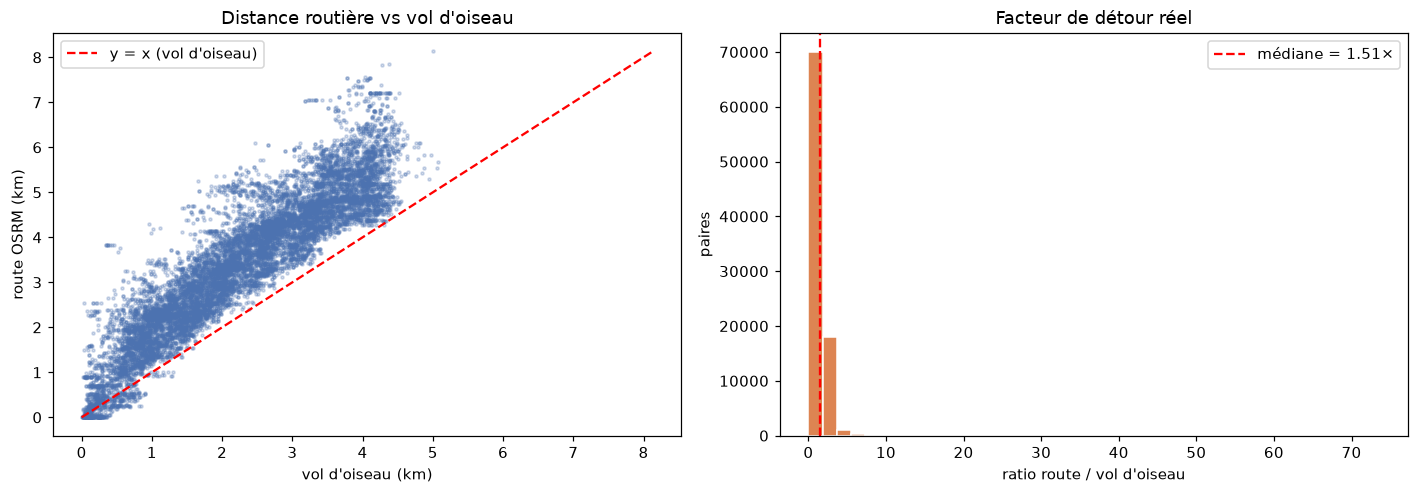

Détour routier : médiane=1.51×, moyenne=1.69× -> l'euclidien sous-estime les distances de ramassage.


In [3]:
mask = ~np.eye(N, dtype=bool)
ratio = ROAD[mask] / np.maximum(HV[mask], 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].scatter(HV[mask][::7]/1000, ROAD[mask][::7]/1000, s=4, alpha=0.25, color="#4C72B0")
lim = max(HV[mask].max(), ROAD[mask].max())/1000
ax[0].plot([0, lim], [0, lim], "r--", label="y = x (vol d'oiseau)")
ax[0].set_xlabel("vol d'oiseau (km)"); ax[0].set_ylabel("route OSRM (km)")
ax[0].set_title("Distance routière vs vol d'oiseau"); ax[0].legend()
ax[1].hist(ratio, bins=40, color="#DD8452", edgecolor="white")
ax[1].axvline(np.median(ratio), color="red", ls="--", label=f"médiane = {np.median(ratio):.2f}×")
ax[1].set_xlabel("ratio route / vol d'oiseau"); ax[1].set_ylabel("paires")
ax[1].set_title("Facteur de détour réel"); ax[1].legend()
savefig("p01_route_vs_voldoiseau.png"); plt.show()
print(f"Détour routier : médiane={np.median(ratio):.2f}×, moyenne={ratio.mean():.2f}× "
      f"-> l'euclidien sous-estime les distances de ramassage.")

## 2. Détection des élèves dispersés (outliers routiers)

Forcer des élèves isolés dans des groupes équilibrés dégrade la compacité. On les **détecte**
(DBSCAN sur la matrice routière) pour les **traiter à part** (ramassage individuel / point de
rendez-vous), et on clusterise le reste proprement.

**🔎 Approche.** On repère les **dispersés** comme le « bruit » d'un DBSCAN basé sur la distance routière : ce sont les élèves loin de tout, à gérer séparément.

eps routier ≈ 933 m | dispersés détectés = 17 | cœur = 283


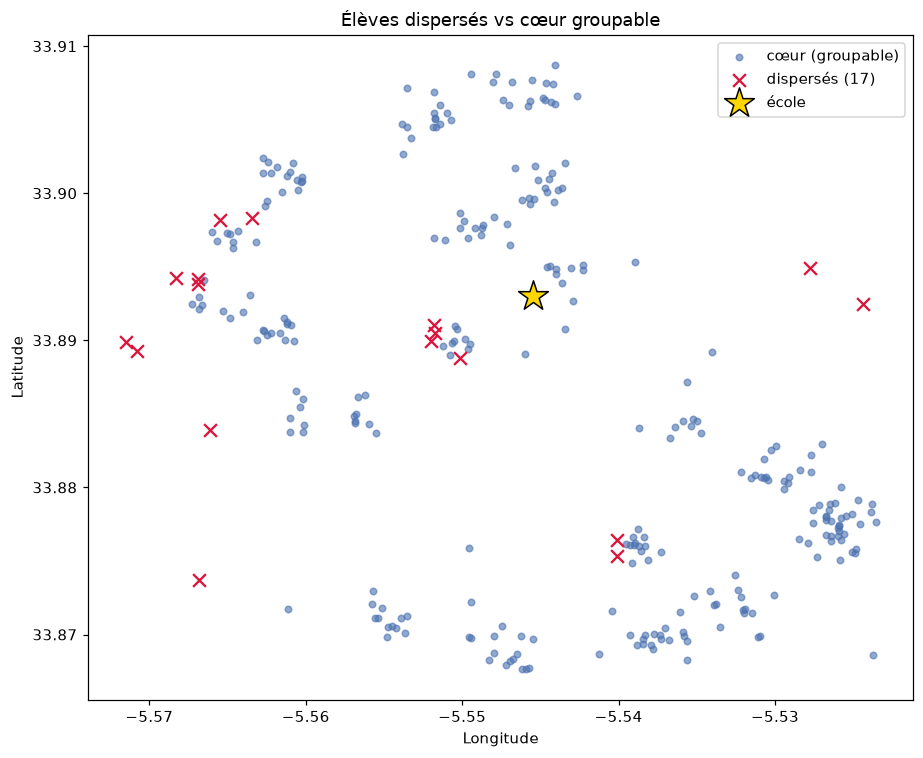

In [4]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

kd = np.sort(np.partition(ROAD + np.eye(N)*1e9, 4, axis=1)[:, 4])   # dist au 5e voisin (routier)
eps = float(np.percentile(kd, 90))
db = DBSCAN(eps=eps, min_samples=5, metric="precomputed").fit(ROAD)
disperses = db.labels_ == -1
core = ~disperses
print(f"eps routier ≈ {eps:.0f} m | dispersés détectés = {disperses.sum()} | cœur = {core.sum()}")

plt.figure(figsize=(8.5, 7))
plt.scatter(df.loc[core,"longitude"], df.loc[core,"latitude"], s=18, c="#4C72B0", alpha=.6, label="cœur (groupable)")
plt.scatter(df.loc[disperses,"longitude"], df.loc[disperses,"latitude"], s=70, c="crimson",
            marker="x", label=f"dispersés ({disperses.sum()})")
plt.scatter([ECOLE[1]], [ECOLE[0]], marker="*", s=420, c="gold", edgecolor="black", label="école")
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.title("Élèves dispersés vs cœur groupable")
plt.legend(); savefig("p02_outliers.png"); plt.show()

## 3. K-médoïdes capacitaire **routier** (cœur des données)

On affecte chaque élève à un **médoïde** (élève « centre » réel) en minimisant la **distance
routière totale**, sous la contrainte `taille ≤ capacité`. L'affectation est un **problème de
transport** (flot à coût minimal) résolu par programmation linéaire : sa solution est entière
(0/1). Les médoïdes sont ensuite réoptimisés (itérations de type k-médoïdes).

**🔎 Approche.** On définit l'**affectation capacitaire** (LP de transport : chaque élève dans un groupe, chaque groupe ≤ capacité) puis les **k-médoïdes routiers** qui réoptimisent les centres.

In [5]:
from scipy.optimize import linprog
from sklearn.cluster import KMeans

def capacitated_assign(C, cap):
    """Affecte n points à k médoïdes en minimisant le coût total, colonne <= cap. C:(n,k)."""
    n, k = C.shape
    import scipy.sparse as sp
    A_eq = sp.lil_matrix((n, n*k))
    for i in range(n): A_eq[i, i*k:(i+1)*k] = 1            # chaque élève -> 1 groupe
    A_ub = sp.lil_matrix((k, n*k))
    for j in range(k): A_ub[j, j::k] = 1                   # taille colonne <= cap
    res = linprog(C.ravel(), A_ub=A_ub.tocsr(), b_ub=np.full(k, cap),
                  A_eq=A_eq.tocsr(), b_eq=np.ones(n), bounds=(0, 1), method="highs")
    return res.x.reshape(n, k).argmax(1)

def kmedoids_cap(D, k, cap, iters=6, seed=RANDOM_STATE):
    """k-médoïdes capacitaire sur matrice de distances D (précalculée, ici routière)."""
    n = len(D)
    # init : KMeans euclidien -> médoïde = point le plus central (routier) de chaque amas
    base = KMeans(k, random_state=seed, n_init=10).fit_predict(XY[core_idx])
    medoids = []
    for j in range(k):
        mem = np.where(base == j)[0]
        if len(mem) == 0: mem = np.array([j])
        sub = D[np.ix_(mem, mem)]; medoids.append(int(mem[sub.sum(1).argmin()]))
    for _ in range(iters):
        labels = capacitated_assign(D[:, medoids], cap)
        new = []
        for j in range(k):
            mem = np.where(labels == j)[0]
            if len(mem) == 0: new.append(medoids[j]); continue
            sub = D[np.ix_(mem, mem)]; new.append(int(mem[sub.sum(1).argmin()]))
        if set(new) == set(medoids): medoids = new; break
        medoids = new
    return labels, medoids

core_idx = np.where(core)[0]
Dcore = ROAD[np.ix_(core_idx, core_idx)]
print(f"Clustering capacitaire routier sur {len(core_idx)} élèves (cœur).")

Clustering capacitaire routier sur 283 élèves (cœur).


## 4. Arbitrage flotte — courbe de Pareto **qualité vs nombre de bus**

Plus on ajoute de bus (k), plus les groupes sont compacts et nets — mais plus la flotte coûte cher.
On balaie k de `⌈N/cap⌉` à `+3` et on trace le compromis : **l'administrateur choisit le point**.

**🔎 Approche.** On balaie le **nombre de bus** et on mesure qualité (silhouette routière) et compacité : la courbe de Pareto rend explicite l'arbitrage qualité ↔ coût de flotte.

   silhouette_routier  compacite_med_m  compacite_max_m  taille_max  faisable
k                                                                            
6               0.392           767.50           2363.8          50      True
7               0.433           725.40           2409.5          50      True
8               0.425           688.30           1795.5          49      True
9               0.427           597.85           1795.5          49      True


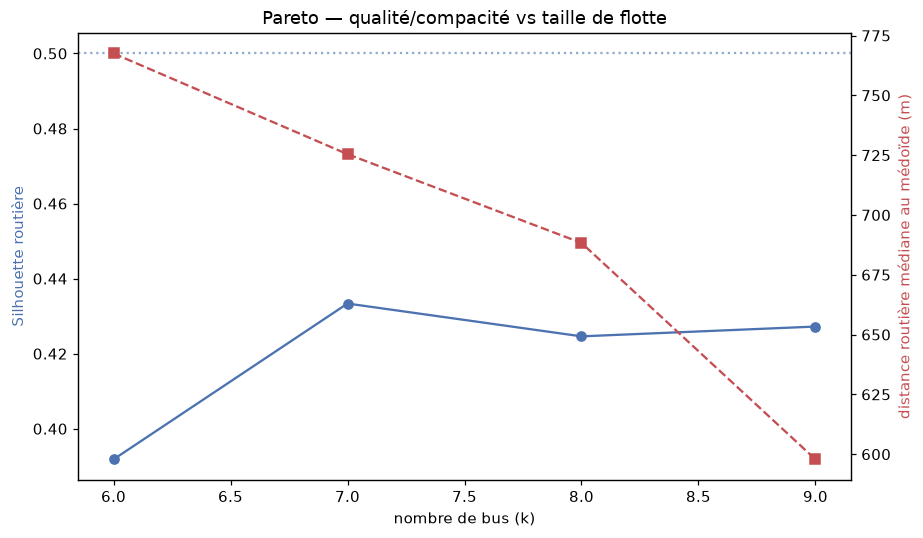

In [6]:
from sklearn.metrics import silhouette_score

def eval_road(D, labels, medoids):
    sizes = np.bincount(labels)
    sil = silhouette_score(D, labels, metric="precomputed") if len(set(labels)) > 1 else np.nan
    dmed = np.array([D[i, medoids[labels[i]]] for i in range(len(labels))])  # dist routière au médoïde
    return {"k": len(set(labels)), "silhouette_routier": sil,
            "compacite_med_m": float(np.median(dmed)), "compacite_max_m": float(dmed.max()),
            "taille_max": int(sizes.max()), "faisable": bool(sizes.max() <= BUS_CAPACITY)}

k_min = math.ceil(len(core_idx) / BUS_CAPACITY)
rows, sols = [], {}
for k in range(k_min, k_min + 4):
    lab, med = kmedoids_cap(Dcore, k, BUS_CAPACITY)
    sols[k] = (lab, med)
    rows.append(eval_road(Dcore, lab, med))
pareto = pd.DataFrame(rows).set_index("k")
print(pareto.round(3))

fig, ax1 = plt.subplots(figsize=(8.5, 5))
ax1.plot(pareto.index, pareto["silhouette_routier"], "o-", color="#4C72B0", label="Silhouette routière")
ax1.set_xlabel("nombre de bus (k)"); ax1.set_ylabel("Silhouette routière", color="#4C72B0")
ax1.axhline(0.5, color="#4C72B0", ls=":", alpha=.6)
ax2 = ax1.twinx()
ax2.plot(pareto.index, pareto["compacite_med_m"], "s--", color="#C44E52", label="Compacité médiane (m)")
ax2.set_ylabel("distance routière médiane au médoïde (m)", color="#C44E52")
plt.title("Pareto — qualité/compacité vs taille de flotte")
savefig("p03_pareto_flotte.png"); plt.show()

## 5. Choix de production et comparaison avec les baselines

On retient le **k au meilleur compromis** : le plus petit k offrant un gain marginal de compacité
faible (genou) **ou** atteignant une silhouette routière satisfaisante. On compare ensuite la
solution retenue aux baselines euclidiennes des notebooks précédents (toutes **évaluées en distance
routière**, pour une comparaison équitable).

**🔎 Approche.** On fixe le k de production (genou / seuil de qualité) et on le compare, **en distance routière**, aux baselines euclidiennes rigides (k=6) et avec slack (k=8) des notebooks précédents.

In [7]:
# Choix : plus petit k dont la silhouette est >= 0.5, sinon meilleure silhouette
feasible = pareto[pareto["faisable"]]
passe = feasible[feasible["silhouette_routier"] >= 0.5]
K_PROD = int(passe.index.min()) if len(passe) else int(feasible["silhouette_routier"].idxmax())
lab_prod, med_prod = sols[K_PROD]
print(f"k de production retenu = {K_PROD} bus")

# Baselines euclidiennes (k-means-constrained) évaluées en distance ROUTIÈRE
from k_means_constrained import KMeansConstrained
def road_metrics_from_coordlabels(labels_full):
    lab = labels_full[core_idx]
    # médoïde routier de chaque groupe (sur le cœur)
    meds = []
    for c in sorted(set(lab)):
        mem = np.where(lab == c)[0]; sub = Dcore[np.ix_(mem, mem)]; meds.append(int(mem[sub.sum(1).argmin()]))
    remap = {c: i for i, c in enumerate(sorted(set(lab)))}
    lab2 = np.array([remap[x] for x in lab])
    return eval_road(Dcore, lab2, meds)

comp = {}
for k in (6, 8):
    full = KMeansConstrained(n_clusters=k, size_max=BUS_CAPACITY, random_state=RANDOM_STATE, n_init=10).fit_predict(XY)
    comp[f"Euclidien capacitaire k={k}"] = road_metrics_from_coordlabels(full)
comp[f"Routier capacitaire k={K_PROD} (PRODUCTION)"] = eval_road(Dcore, lab_prod, med_prod)
cmp = pd.DataFrame(comp).T[["silhouette_routier","compacite_med_m","compacite_max_m","taille_max","faisable"]]
print(cmp.round(3))

k de production retenu = 7 bus


                                     silhouette_routier compacite_med_m  \
Euclidien capacitaire k=6                      0.284884          836.95   
Euclidien capacitaire k=8                      0.421305           703.4   
Routier capacitaire k=7 (PRODUCTION)           0.433362           725.4   

                                     compacite_max_m taille_max faisable  
Euclidien capacitaire k=6                    2989.75         50     True  
Euclidien capacitaire k=8                     2486.6         47     True  
Routier capacitaire k=7 (PRODUCTION)          2409.5         50     True  


**🔎 Approche.** Carte finale exploitable : groupes routiers colorés, **médoïdes** (élèves-centres réels), élèves dispersés et école.

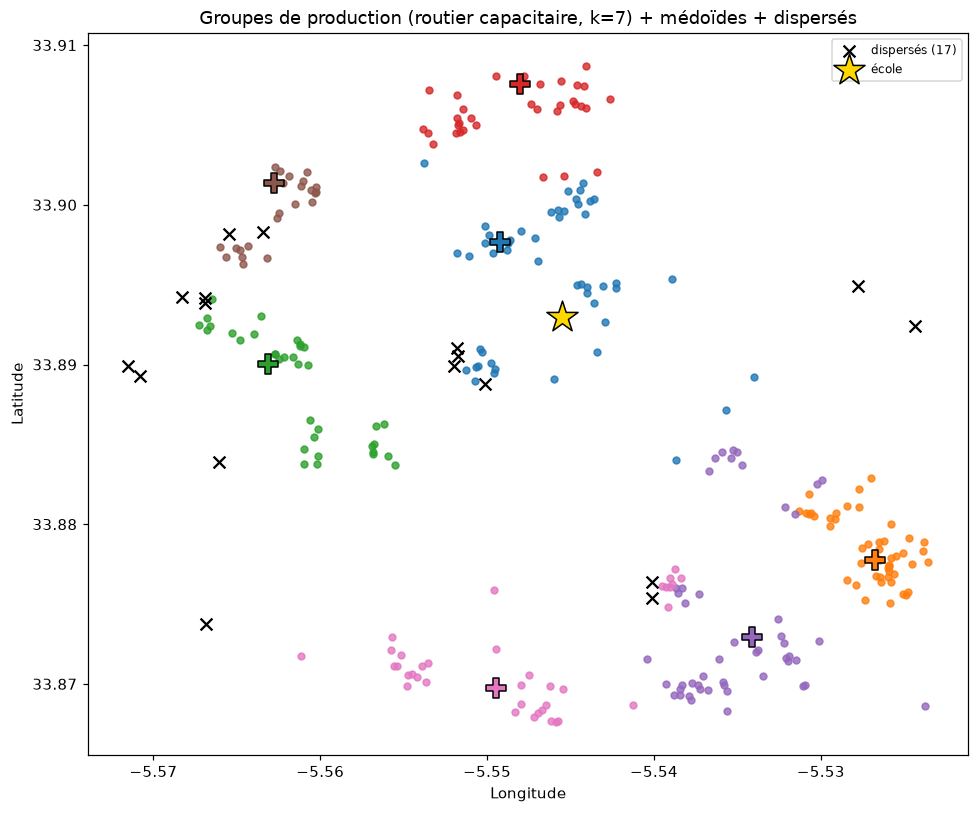

In [8]:
# Carte finale de production : groupes routiers + médoïdes + dispersés + école
gcol = colormaps["tab10"].resampled(max(K_PROD, 10))
plt.figure(figsize=(9, 7.5))
for j in range(K_PROD):
    idx = core_idx[lab_prod == j]
    plt.scatter(df.loc[idx,"longitude"], df.loc[idx,"latitude"], s=20, color=gcol(j), alpha=.8)
    m = core_idx[med_prod[j]]
    plt.scatter(df.loc[m,"longitude"], df.loc[m,"latitude"], marker="P", s=160,
                color=gcol(j), edgecolor="black", zorder=5)
plt.scatter(df.loc[disperses,"longitude"], df.loc[disperses,"latitude"], s=60, c="black",
            marker="x", label=f"dispersés ({disperses.sum()})")
plt.scatter([ECOLE[1]], [ECOLE[0]], marker="*", s=460, c="gold", edgecolor="black", label="école")
plt.title(f"Groupes de production (routier capacitaire, k={K_PROD}) + médoïdes + dispersés")
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.legend(fontsize=8)
savefig("p04_groupes_production.png"); plt.show()

## 6. Gel de la configuration de production

On fige la stratégie retenue (algorithme, distance, k, gestion des dispersés, métriques routières)
dans un artefact JSON, consommé par MS6 et traçable (CDC).

**🔎 Approche.** On **gèle** la configuration de production (stratégie, distance routière, k, gestion des dispersés, métriques) dans un JSON versionné pour MS6 et la traçabilité.

In [9]:
# Affectation finale des dispersés : médoïde routier le plus proche (signalé "ramassage individuel")
labels_all = np.full(N, -1)
labels_all[core_idx] = lab_prod
for i in np.where(disperses)[0]:
    labels_all[i] = int(np.argmin([ROAD[i, core_idx[m]] for m in med_prod]))

prod_metrics = eval_road(Dcore, lab_prod, med_prod)
config = {
    "version": "ms6-clustering-v3-routier",
    "strategie": "k-médoïdes capacitaire sur distance routière OSRM",
    "distance": "OSRM driving (réseau Meknès), matrice symétrisée",
    "capacite_bus": BUS_CAPACITY, "k_production": K_PROD,
    "n_eleves": int(N), "n_disperses_individuel": int(disperses.sum()),
    "metriques_routieres": {k: (None if (isinstance(v,float) and math.isnan(v)) else v)
                            for k, v in prod_metrics.items()},
    "gestion_disperses": "détectés (DBSCAN routier), ramassage individuel / médoïde le plus proche",
    "arbitrage_flotte": "courbe de Pareto qualité vs nb de bus (décision admin)",
    "dateCalcul": None,
}
Path("production_config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(config, indent=2, ensure_ascii=False))

{
  "version": "ms6-clustering-v3-routier",
  "strategie": "k-médoïdes capacitaire sur distance routière OSRM",
  "distance": "OSRM driving (réseau Meknès), matrice symétrisée",
  "capacite_bus": 50,
  "k_production": 7,
  "n_eleves": 300,
  "n_disperses_individuel": 17,
  "metriques_routieres": {
    "k": 7,
    "silhouette_routier": 0.43336200418311355,
    "compacite_med_m": 725.4,
    "compacite_max_m": 2409.5,
    "taille_max": 50,
    "faisable": true
  },
  "gestion_disperses": "détectés (DBSCAN routier), ramassage individuel / médoïde le plus proche",
  "arbitrage_flotte": "courbe de Pareto qualité vs nb de bus (décision admin)",
  "dateCalcul": null
}


## 7. Conclusion — stratégie de production recommandée

**Recommandation finale pour MS6**, fondée sur les résultats :

1. **Distance routière OSRM** (et non euclidienne) pour clusteriser et évaluer — le détour réel est
   de ~1.5–1.7×, ignoré par l'euclidien.
2. **K-médoïdes capacitaire routier** (affectation par flot à coût minimal) : garantit
   `taille ≤ capacité` tout en minimisant la distance de ramassage réelle, sans imposer l'égalité
   rigide qui dégradait la qualité.
3. **Traitement séparé des dispersés** : détectés automatiquement, ramassage individuel / point de
   rendez-vous — au lieu de polluer les groupes.
4. **Arbitrage flotte par Pareto** : le nombre de bus est une **décision métier** exposée à
   l'administrateur (qualité vs coût), pas un nombre figé.

**Vers la suite :** la matrice de durées OSRM (`data/osrm_dur_s.npy`) et les médoïdes alimentent
directement la **prédiction d'ETA (S9)** et l'**optimisation des tournées VRP (S10)** ; la confiance
GMM et la stabilité ARI (notebook 2) déclenchent les **recalculs évolutifs (S8)**.

---

## Enrichissement pour le mémoire — isoler l'apport, et stabiliser le choix de `k`

Ce notebook compare « euclidien k=8 → 0,4213 » à « routier k=7 → 0,4334 » et attribue l'écart à la
distance routière. Mais **trois facteurs changent en même temps** : la distance, l'algorithme et le
nombre de bus. Le gain pouvait venir du changement de `k`.

C'est d'autant plus gênant que cette thèse porte **deux** conclusions du projet : la qualité du
clustering, *et* l'explication du résultat CVRP de MS5 (« l'information géographique est injectée
avant le routage »).

Les figures ci-dessous isolent l'apport réel, puis exposent un défaut bien plus grave que la
question de la distance : **le nombre de bus dépendait de l'ordre des lignes renvoyées par
PostgreSQL**.

> ⚠️ **Ces cellules sont en lecture seule.** Elles chargent les JSON de résultats déjà produits
> (`data/ablation_distance.json`, `data/sensibilite_ordre.json`, `data/stabilite.json`,
> `data/churn_apres_correctif.json`, `data/quality_baseline.json`). Aucun clustering n'est
> recalculé, et ni `production_config.json` ni `quality_baseline.json` ne sont réécrits. Les
> figures partent en PDF + PNG 300 dpi dans `notebooks/figures/`.


### 1. L'ablation propre — un seul facteur varie

Même algorithme, même `k`, même graine. **Seule la matrice de distances change.**

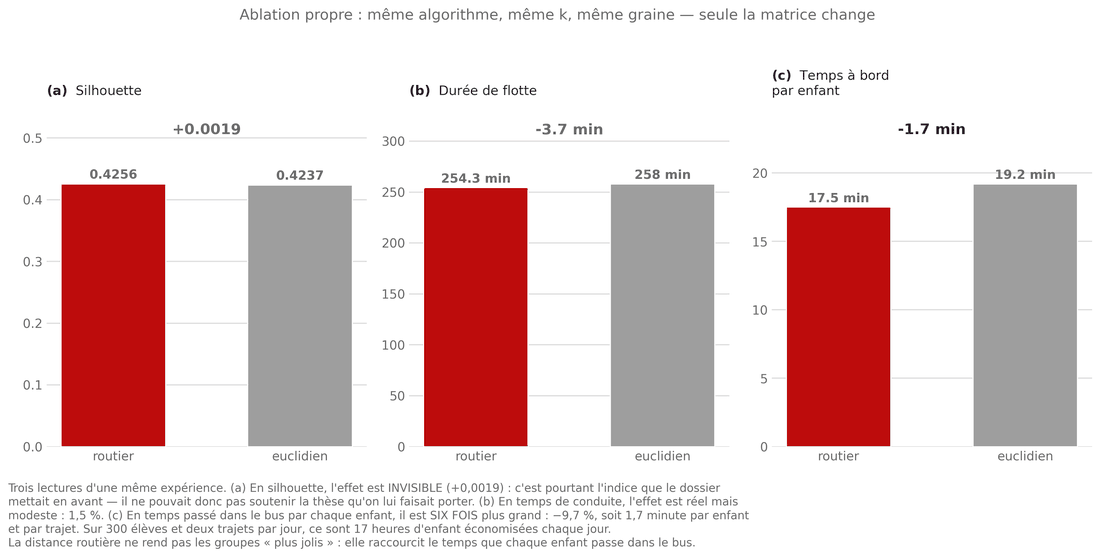

In [ ]:
# Import robuste : certains notebooks font os.chdir(".."), le dossier
# notebooks/ n'est alors plus sur sys.path.
import sys, pathlib
_d = pathlib.Path.cwd()
_d = _d if (_d / "gen_figures_memoire.py").exists() else _d / "notebooks"
sys.path.insert(0, str(_d))
import gen_figures_memoire as gfm
gfm.fig_ablation_distance()

### 2. La cause racine : un argmax sur du bruit

`choisir_k` retenait le `k` de meilleure silhouette parmi les candidats du Pareto. Encore faut-il
que ces silhouettes soient discernables. Dix graines par `k` répondent à la question.

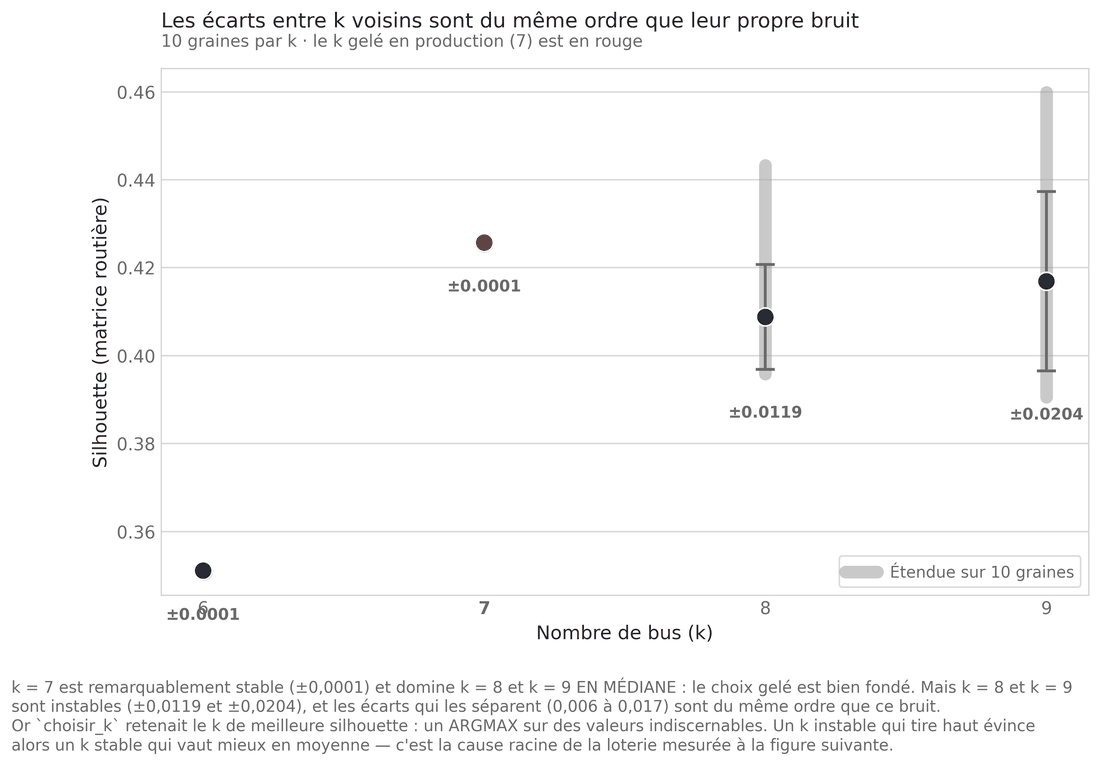

In [ ]:
# Import robuste : certains notebooks font os.chdir(".."), le dossier
# notebooks/ n'est alors plus sur sys.path.
import sys, pathlib
_d = pathlib.Path.cwd()
_d = _d if (_d / "gen_figures_memoire.py").exists() else _d / "notebooks"
sys.path.insert(0, str(_d))
import gen_figures_memoire as gfm
gfm.fig_bruit_silhouette()

### 3. La conséquence : une loterie sur la flotte

Trente permutations des **mêmes** 300 élèves, même graine, même matrice OSRM.

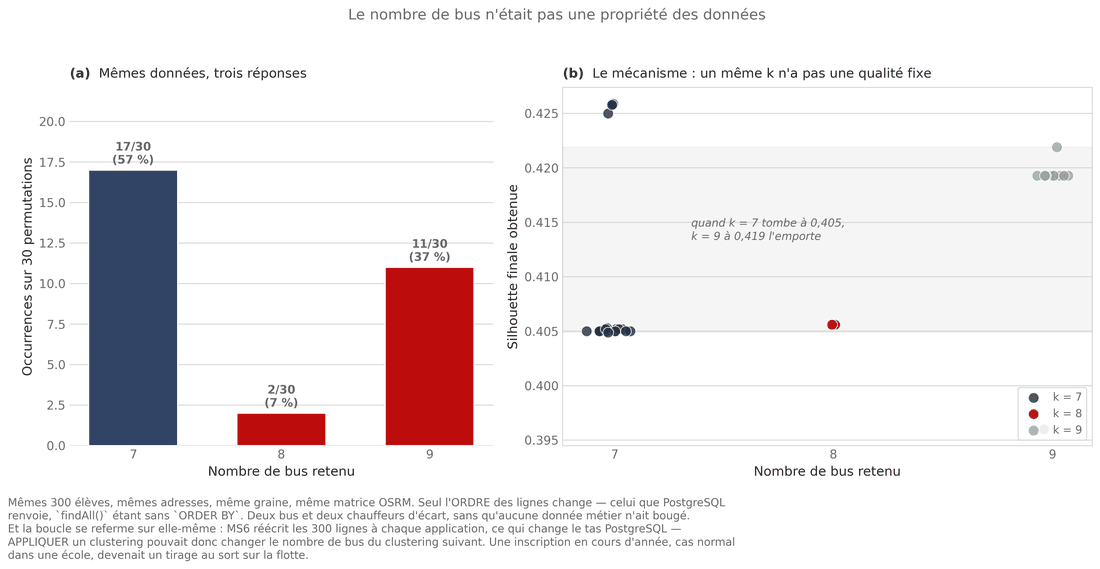

In [ ]:
# Import robuste : certains notebooks font os.chdir(".."), le dossier
# notebooks/ n'est alors plus sur sys.path.
import sys, pathlib
_d = pathlib.Path.cwd()
_d = _d if (_d / "gen_figures_memoire.py").exists() else _d / "notebooks"
sys.path.insert(0, str(_d))
import gen_figures_memoire as gfm
gfm.fig_sensibilite_ordre()

### 4. Ce que cela coûte aux familles

Le churn — pourcentage d'élèves changeant de bus entre deux recalculs — est ce que les familles
subissent réellement, et il n'était mesuré nulle part. Trois règles de choix sont comparées sur la
même simulation d'inscriptions.

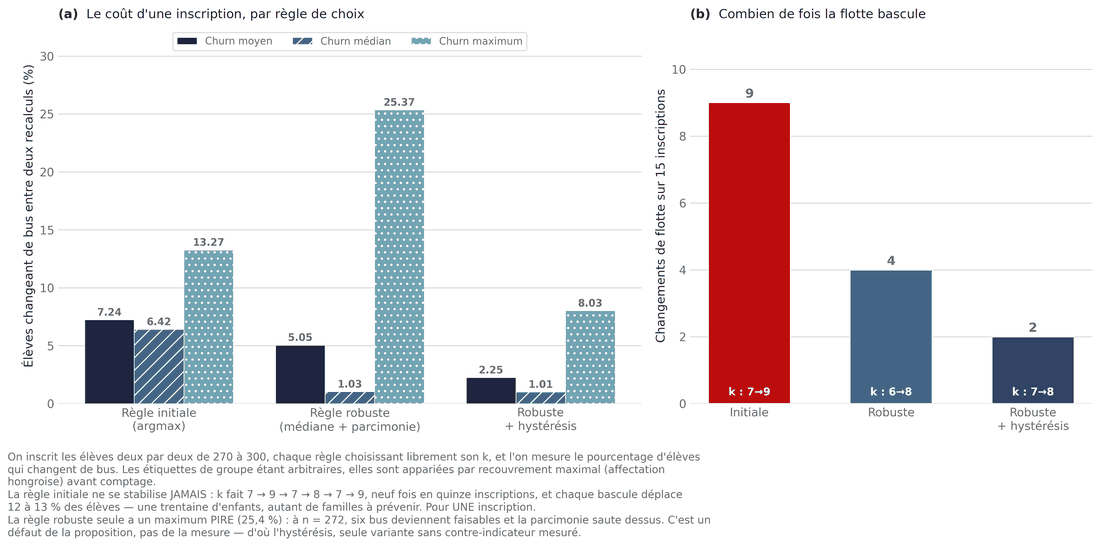

In [ ]:
# Import robuste : certains notebooks font os.chdir(".."), le dossier
# notebooks/ n'est alors plus sur sys.path.
import sys, pathlib
_d = pathlib.Path.cwd()
_d = _d if (_d / "gen_figures_memoire.py").exists() else _d / "notebooks"
sys.path.insert(0, str(_d))
import gen_figures_memoire as gfm
gfm.fig_churn()

### 5. Le correctif déployé, mesuré

Deux changements indissociables dans `selection.py` : **médiane** sur plusieurs initialisations
pour comparer les `k`, puis **hystérésis** sur la flotte. Faits séparément, ils ne suffisent pas.

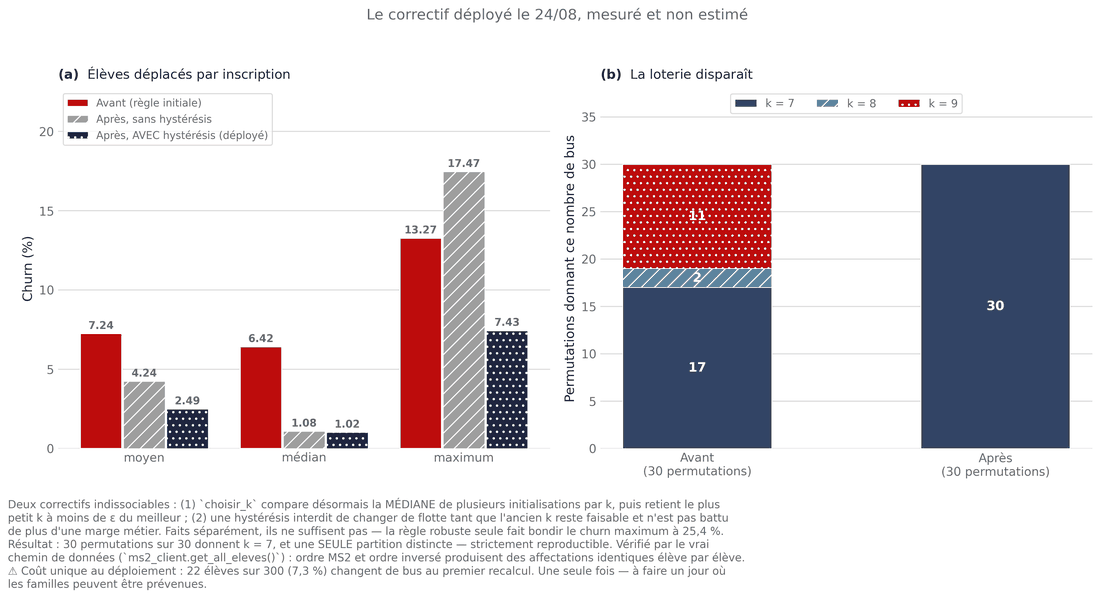

In [ ]:
# Import robuste : certains notebooks font os.chdir(".."), le dossier
# notebooks/ n'est alors plus sur sys.path.
import sys, pathlib
_d = pathlib.Path.cwd()
_d = _d if (_d / "gen_figures_memoire.py").exists() else _d / "notebooks"
sys.path.insert(0, str(_d))
import gen_figures_memoire as gfm
gfm.fig_correctif()

### 6. Le garde-fou qualité, et le cliquet qu'il a fallu défaire

`quality.py` compare chaque run à une référence roulante. Ce mécanisme s'est bloqué pendant cinq
semaines, d'une façon qui vaut d'être connue : elle se reproduit dès qu'une référence ne peut être
mise à jour que lorsqu'elle est satisfaite.

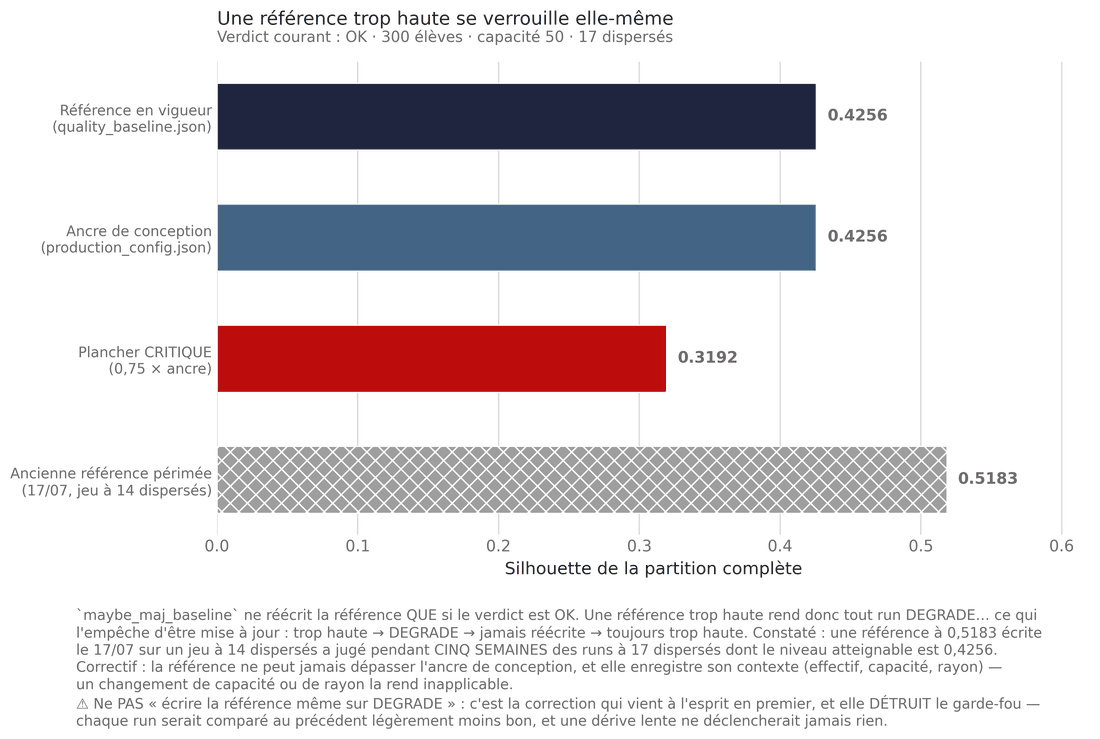

In [ ]:
# Import robuste : certains notebooks font os.chdir(".."), le dossier
# notebooks/ n'est alors plus sur sys.path.
import sys, pathlib
_d = pathlib.Path.cwd()
_d = _d if (_d / "gen_figures_memoire.py").exists() else _d / "notebooks"
sys.path.insert(0, str(_d))
import gen_figures_memoire as gfm
gfm.fig_qualite()

### Ce que cette section apporte au mémoire

| Question | Réponse mesurée |
|---|---|
| La distance routière vaut-elle son coût ? | **Oui, mais pas là où on regardait** : +0,0019 de silhouette (invisible), −1,5 % de conduite, et **−9,7 % de temps à bord par enfant** |
| Le nombre de bus est-il une propriété des données ? | **Non, il l'était si peu qu'il variait de 7 à 9** selon l'ordre des lignes en base |
| Le correctif a-t-il fonctionné ? | **Oui** : 30 permutations sur 30 donnent k = 7 et **une seule partition distincte**. Churn médian 6,42 % → 1,02 %, changements de flotte 9 → 0 |
| Le garde-fou qualité fonctionnait-il ? | **Non** : bloqué en DEGRADE pendant cinq semaines par une référence trop haute qui s'auto-verrouillait |

**Trois erreurs de conception commises *pendant* le correctif, toutes attrapées par la mesure** —
à relire avant de retoucher `selection.py` :

- **ε global** : la dispersion d'un `k` très instable élargissait la marge au point de faire passer
  `k = 6` pour l'égal de `k = 7`. ε doit être **propre à la comparaison**.
- **Meilleur essai pour comparer** : prendre le meilleur de N par `k` favorise **mécaniquement le
  plus bruité** (on compare des maxima d'échantillons de variances différentes) — le service
  répondait alors k = 9 dans 14 cas sur 30. D'où : **médiane pour choisir `k`**, meilleur essai
  pour la partition livrée **une fois `k` fixé**.
- **Une seule marge pour deux questions** : ε statistique (« ces deux `k` sont-ils discernables ? »,
  ≈ 0,005) ≠ marge d'hystérésis (« ce gain justifie-t-il de redistribuer toute l'école ? », 0,03).
  Avec la seule marge statistique, l'hystérésis ne se déclenchait jamais.

> **Leçon de méthode** : le benchmark exécutait la vraie fonction de production **sans emprunter le
> chemin de production** — élèves triés par id depuis le CSV, au lieu de l'ordre du tas PostgreSQL
> que renvoie MS2. Il avait donc publié « le pipeline produit k = 8 », ce qui était faux.
> Un benchmark doit consommer **la même source de données que le service**. Voir
> [`docs/MS6_BENCHMARK_DISTANCE.md`](../../docs/MS6_BENCHMARK_DISTANCE.md) §5.
